# GPT-2 from scratch: demo notebook

Loads a trained checkpoint, generates text, inspects next-token probabilities and shows attention maps.
Everything uses only this repository's own code (`src/model.py`, `src/tokenizer.py`, `src/generate.py`).

**Run it:** locally from the repo root (`jupyter lab notebooks/demo.ipynb`) or on Colab:
`!git clone <your repo url> && %cd <repo> && !pip install -r requirements.txt`, then run all cells.
By default it picks the best checkpoint it can find (your T4-trained `checkpoints/small`, else the CPU demo models);
change `CKPT_EN` / `CKPT_AM` below to use another.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # started from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch, matplotlib.pyplot as plt
%matplotlib inline

from src.generate import generate, load_model, tokenizer_for_checkpoint, encode_prompt, last_token_logits, next_token_probs
from src.tokenizer import token_labels
from src.utils import setup_ethiopic_font

print("Ge'ez-capable plotting font:", setup_ethiopic_font())     # so Amharic labels render in plots
torch.manual_seed(0)

Ge'ez-capable plotting font: Noto Sans Ethiopic


In [2]:
def first_existing(*candidates):
    for c in candidates:
        if (ROOT / c).exists():
            return ROOT / c
    return None

CKPT_EN = first_existing("checkpoints/small/ckpt_best.pt", "app/checkpoints/english/model.pt", "checkpoints/demo_english/ckpt_best.pt")
CKPT_AM = first_existing("checkpoints/amharic/ckpt_best.pt", "app/checkpoints/amharic/model.pt", "checkpoints/demo_amharic/ckpt_best.pt")
print("English checkpoint:", CKPT_EN)
print("Amharic checkpoint:", CKPT_AM)

def load(path):
    model, ck = load_model(path)
    return model, tokenizer_for_checkpoint(ck, path), ck

model, tok, ck = load(CKPT_EN)
print(f"{model.num_params():,} parameters | vocab {tok.vocab_size} | trained {ck.get('step')} steps | best val loss {ck.get('best_val_loss'):.3f}")

English checkpoint: C:\Users\bethe\Desktop\GPT-2\checkpoints\small\ckpt_best.pt
Amharic checkpoint: C:\Users\bethe\Desktop\GPT-2\app\checkpoints\amharic\model.pt


10,770,816 parameters | vocab 65 | trained 0 steps | best val loss 4.258


## 1. Model: parameter breakdown

In [3]:
model.print_param_breakdown()

component                         params    share
token embedding                   24,960     0.2%
position embedding                98,304     0.9%
final layernorm                      768     0.0%
lm_head (0 if tied)                    0     0.0%
all blocks: attention          3,548,160    32.9%
all blocks: mlp                7,089,408    65.8%
all blocks: layernorms             9,216     0.1%
TOTAL                         10,770,816
(one block = 1,774,464 params; n_layer = 6; tied = True)


## 2. Generate text
Greedy picks the single most likely token every step; temperature sampling draws from the distribution (lower = safer, higher = more varied).

In [4]:
def sample(model, tok, prompt, n=300, **kw):
    idx = encode_prompt(tok, prompt, "cpu")
    out = generate(model, idx, n, generator=torch.Generator().manual_seed(1337), **kw)
    return tok.decode(out[0].tolist())

print("--- temperature 0.8 ---");  print(sample(model, tok, "ROMEO:\n", 300, temperature=0.8))
print("\n--- greedy ---");         print(sample(model, tok, "ROMEO:\n", 200, greedy=True))

--- temperature 0.8 ---


ROMEO:
-pzlWaH ;czde.pwEyI,YzrzlGu-?YeNY
ij
o
LzzjgeUUS-AAUUFiiVT'G HTssPPW;,Sn$zOAnsz-imHzcAkfZfYYgSTRTNBE:myOzx. qVh -gLcJJlZHPXBvZNU&fg?nU'ZzMMHZ?-gqIpoZv-A&Xn3ziSKOSqGS vW?FzkgttIba.m;33RP
wq::gpssM'xIZZiEhOrXIkVSTQsXz?eqSnTA&&i3xBUhO3e;;cecfsllnnXeCSZ'YS?$YxPyCtRZD;;?uUkfVmXgEzh.l!rlye. auUWCOwUFNC.gQ

--- greedy ---


ROMEO:


















,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,uuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuu


### Temperature comparison, same prompt and seed

In [5]:
for T in (0.2, 0.5, 1.0, 1.5):
    print(f"\n=== T = {T} ===")
    print(sample(model, tok, "ROMEO:\n", 150, temperature=T))


=== T = 0.2 ===


ROMEO:

pzzzzz     3.pGEEEEEErzzGGGGGeeeeiiiiiizzXXXXXXXXXXXXXXXXXXXXTXXXXXiXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX

=== T = 0.5 ===


ROMEO:
-pzllaH ;czde.pwEyv,YzrzlGu-?YeNO
ij
o
.zzjgeUUS-b.UUFiiVT'G TTsstPW;,Sn$ OAngz-imHzcccxZfYYgSTRziiEcmyOzx.VqVV -gLcxglZZPXBvINU&fg?nnnZzQoXZ?-gqIpoZv

=== T = 1.0 ===


ROMEO:
-pzlWaS ;czde.pwEyI,YzrzlGu-?YeNY
ijbo
LzzjgeUUS-AAU'FiiVT'G HTssPPW;,Sn$zOAnsz-imHzcAkfZfYYgS;RTNBE:myOzx. qVh -gLcJJlZHPXBvZNU&fg?nU'qG-dXE?-gqYpoZv

=== T = 1.5 ===


ROMEO:
CpzlWaS ;czde.pwEyI,YzrzlGu-?YeNY
ijbo
Lzzj$eUKS-AAU FisVJiG HTssPPW;,Se$zOAnsz-imHzcAkfZfYSgS;RTNBE:myOzx. qVh -gLcJJlZHPXBvZNA&fg?nUKqzMdXE?-gqYpoZv


## 3. Next-token probabilities
The model outputs one probability per vocabulary entry. Here are the top 10 after a prompt.

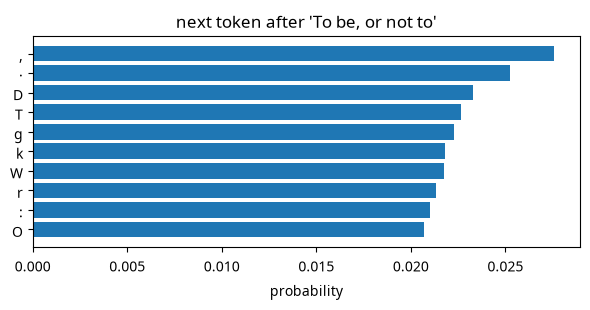

In [6]:
prompt = "To be, or not to"
idx = encode_prompt(tok, prompt, "cpu")
probs = next_token_probs(last_token_logits(model, idx)[None])[0]
p, i = probs.topk(10)
labels = token_labels(tok, i.tolist())
plt.figure(figsize=(6, 3.2)); plt.barh(labels[::-1], p.flip(0)); plt.xlabel("probability")
plt.title(f"next token after {prompt!r}"); plt.tight_layout(); plt.show()

## 4. Attention maps
Row = query token, column = key token; the upper triangle is zero because of the causal mask.

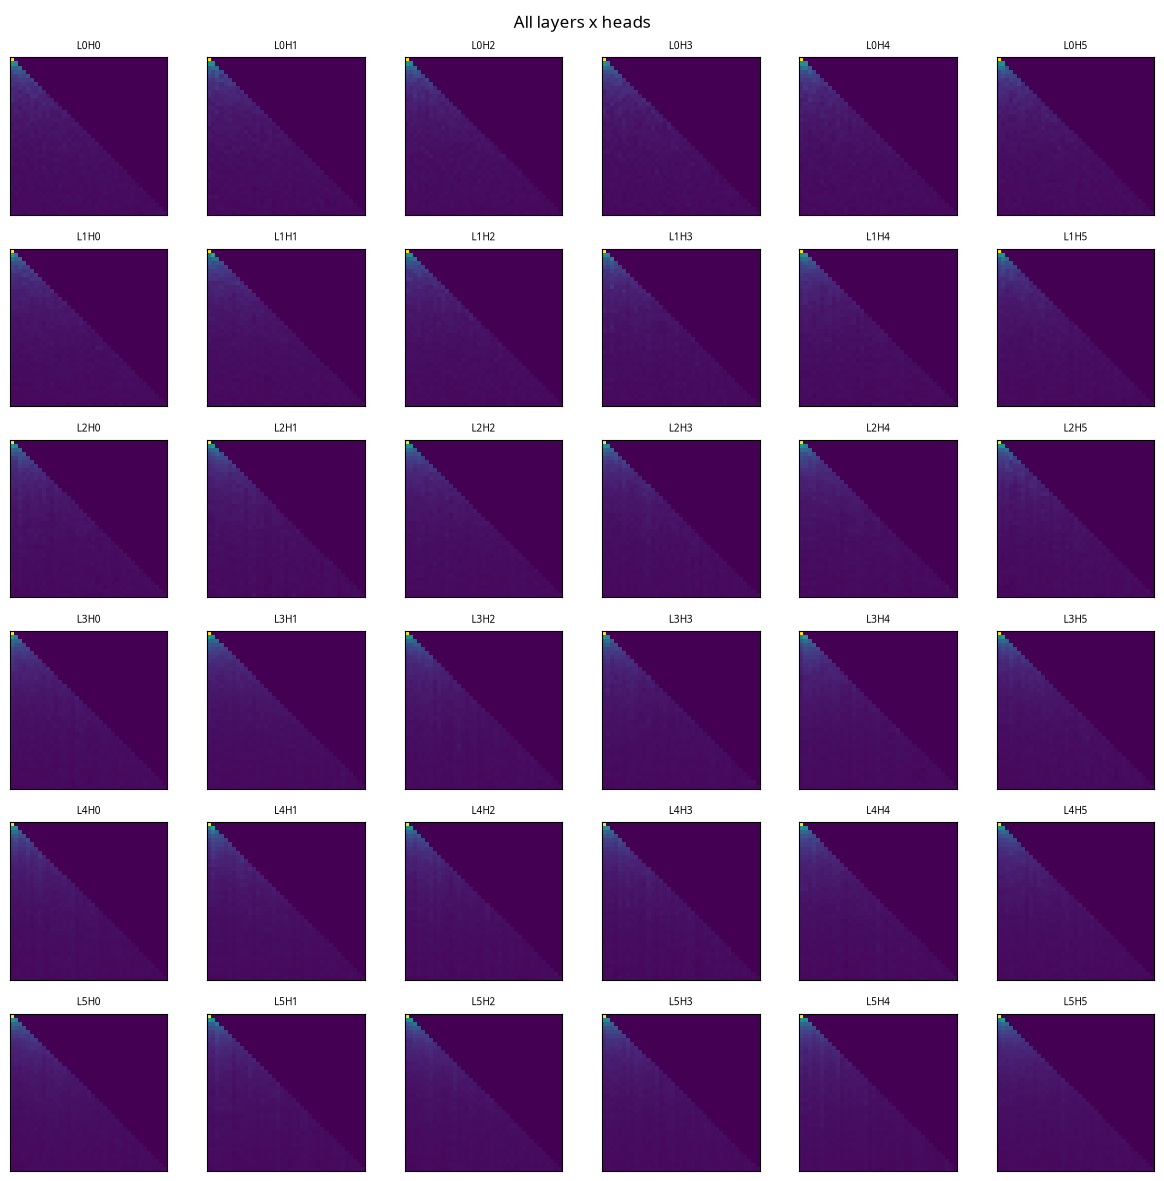

In [7]:
sentence = "ROMEO:\nO, where art thou? Speak, speak!"
ids = tok.encode(sentence)[: model.cfg.block_size]
_, _, attns = model(torch.tensor([ids]), return_attn=True)          # list of (1, n_head, T, T), one per layer
toks = token_labels(tok, ids)

n_layer, n_head = model.cfg.n_layer, model.cfg.n_head
fig, axes = plt.subplots(n_layer, n_head, figsize=(2.0 * n_head, 2.0 * n_layer), squeeze=False)
for l in range(n_layer):
    for h in range(n_head):
        axes[l][h].imshow(attns[l][0, h].detach(), cmap="viridis", vmin=0, vmax=1)
        axes[l][h].set_xticks([]); axes[l][h].set_yticks([]); axes[l][h].set_title(f"L{l}H{h}", fontsize=7)
fig.suptitle("All layers x heads"); plt.tight_layout(); plt.show()

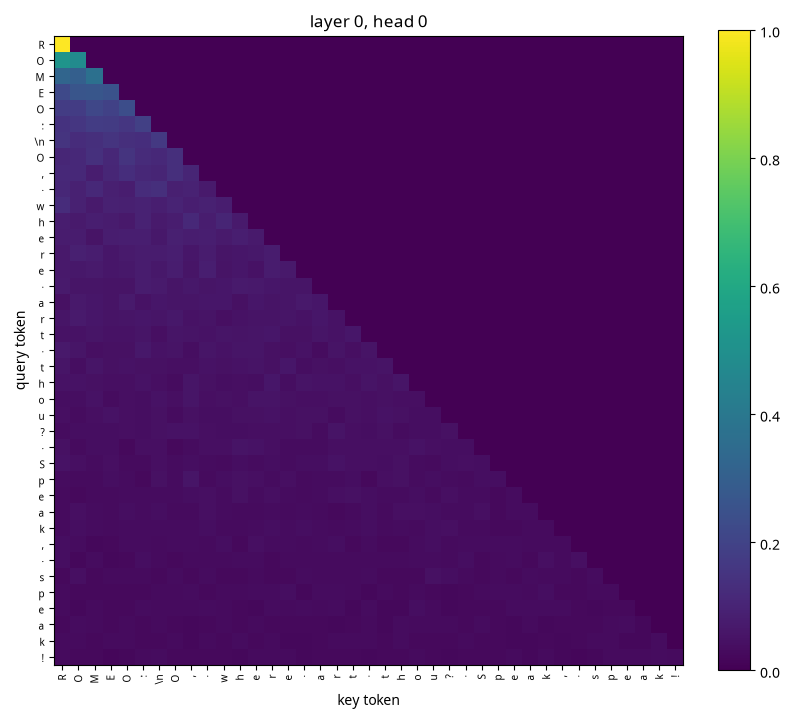

In [8]:
layer, head = 0, 0                                                  # change these to explore
A = attns[layer][0, head].detach()
plt.figure(figsize=(8, 8)); plt.imshow(A, cmap="viridis")
plt.xticks(range(len(toks)), toks, rotation=90, fontsize=7); plt.yticks(range(len(toks)), toks, fontsize=7)
plt.xlabel("key token"); plt.ylabel("query token"); plt.title(f"layer {layer}, head {head}"); plt.colorbar(fraction=0.046); plt.tight_layout(); plt.show()
# a "previous-token" head would show a bright line just below the diagonal; run experiments/exp9_attention.py for statistics

## 5. KV cache: same output, faster
Greedy decoding with and without the cache must give identical text; the cache avoids recomputing keys/values of earlier tokens.

In [9]:
idx = encode_prompt(tok, "ROMEO:", "cpu")
n = model.cfg.block_size - idx.size(1)
res = {}
for name, cache in (("no cache", False), ("kv cache", True)):
    t0 = time.time(); out = generate(model, idx, n, greedy=True, use_cache=cache); res[name] = (out, n / (time.time() - t0))
print({k: f"{v[1]:.0f} tokens/s" for k, v in res.items()}, "| identical:", torch.equal(res["no cache"][0], res["kv cache"][0]))

{'no cache': '2 tokens/s', 'kv cache': '8 tokens/s'} | identical: True


## 6. Training curves of this checkpoint

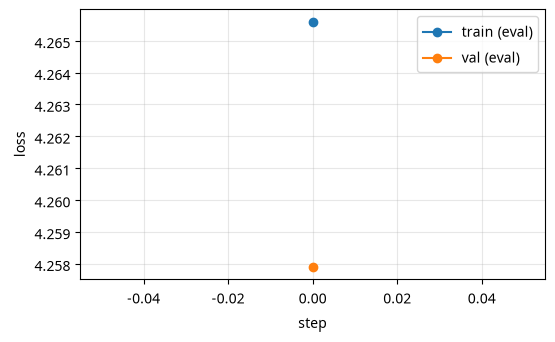

In [10]:
import csv
log = CKPT_EN.parent / "log.csv"
if log.exists():
    rows = list(csv.DictReader(open(log, encoding="utf-8")))
    def col(c): return [(int(r["step"]), float(r[c])) for r in rows if r.get(c)]
    plt.figure(figsize=(6, 3.5))
    for c, lab in (("eval_train_loss", "train (eval)"), ("eval_val_loss", "val (eval)")):
        xs, ys = zip(*col(c)); plt.plot(xs, ys, "o-", label=lab)
    plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("no log.csv next to this checkpoint (exported checkpoints carry only the weights)")

## 7. Amharic (Ge'ez script)
Same code, different tokenizer and corpus. Byte-level BPE needs 3 tokens per Ge'ez letter before any merge; character-level models need a bigger alphabet.

In [11]:
if CKPT_AM:
    am_model, am_tok, am_ck = load(CKPT_AM)
    print(f"{am_model.num_params():,} parameters | vocab {am_tok.vocab_size} | best val loss {am_ck.get('best_val_loss'):.3f}")
    for T in (0.5, 0.8, 1.0):
        print(f"\n=== T = {T} ===")
        print(sample(am_model, am_tok, "የኢትዮጵያ ", 200, temperature=T))
else:
    print("no Amharic checkpoint found: train one with `python -m src.train --config configs/demo_amharic.yaml`")

461,440 parameters | vocab 377 | best val loss 2.130

=== T = 0.5 ===


የኢትዮጵያ የዓለም አቀፉ በማደረግ የሚያስረዳል። በአውሮፓ የተባለው አገሪቱ የአሜሪካ ጊዜ የተለያዩ ሰው ቡድን በአንድ የሚያደርጋቸው የሚያስፈልጋቸውን አገራት የሚያልፍ የተለያዩ ክልልን አስተዳደሩ የምትፈልጋቸው እንዲመለስ አስተዳደረጉ እንዲወጣ እንደሚያስችላል ብለዋል። በዚህ አባላት ከፍተኛ የሚገኙ የሚያደርጉት የተለያዩ የሚያስ

=== T = 0.8 ===


የኢትዮጵያ ሚኒስቴር ከሚገኙ ደረጃ ለመጀመርተዋል። በኤምሬትስ በመቀበል በሚሲያ ተከትሎ በላይ የፈረንሳይ ቡድኖችን በአውሮፓ ላይ መጠን አቶ አበባ ሥራ አገራት። በተል ያለ አገራትና የንግድ ውስጥ የምንፈልጉትና የፍፃሜ መቀላቸው አገልግሎት ጀምሮ ትልቅ ላይ የእግር ኳስ ፕሬዚዳንት እንዲከፍ መገጠማቸውን ከጣም በፊት የክትባቱ ያሳያ

=== T = 1.0 ===


የኢትዮጵያ ሚኒስቴር ከ8000 ሜትር በጀት ተናግረዋል። ከ207 ሰዓት መንግሥት ተከፍቷል። የአክሎምፒክ ሜቶን የተሰማው የሚኖሯ ጋር ከጥሬ ሌላ የህዝቧ ገገ ግንኙነት በላይ አሸናፊነት ንብረት ምርቶች ጥቃት ባለሙያዎች አንዱ ወታደራዊ ቡድን ጀምሮ ትልቅ ላይ እያጠናቁ ቀደም፣ በዚህም አሁንም መገጠማቸው ከአውሮፓ ካንሰሩ በኋላ ያሳዘ


In [12]:
from src.tokenizer import BPETokenizer, CharTokenizer, load_tokenizer
text = "ሰላም ለዓለም። የኢትዮጵያ ሕዝብ ሰላም ነው።"
tok_dir = ROOT / "assets" / "tokenizers"
if (tok_dir / "amharic_bpe_byte.json").exists():
    for name in ("char", "bpe_char", "bpe_byte"):
        t = load_tokenizer(tok_dir / f"amharic_{name}.json")
        t = t.truncated(1000) if name != "char" else t
        ids = t.encode(text)
        print(f"{name:9s} vocab {t.vocab_size:5d}  {len(ids):3d} tokens  ({len(text.encode()) / len(ids):.2f} bytes/token):", " | ".join(token_labels(t, ids, visible=False)))
else:
    print("run `python experiments/exp11_amharic_study.py` to build assets/tokenizers/")

char      vocab   351   28 tokens  (2.64 bytes/token): ሰ | ላ | ም |   | ለ | ዓ | ለ | ም | ። |   | የ | ኢ | ት | ዮ | ጵ | ያ |   | ሕ | ዝ | ብ |   | ሰ | ላ | ም |   | ነ | ው | ።
bpe_char  vocab  1000   14 tokens  (5.29 bytes/token): ሰ | ላ | ም |  ለ | ዓለም | ። |  የኢትዮጵያ |  ሕ | ዝብ |  ሰ | ላ | ም |  ነው | ።
bpe_byte  vocab  1000   14 tokens  (5.29 bytes/token): ሰ | ላ | ም |  ለ | ዓለም | ። |  የኢትዮጵያ |  ሕ | ዝብ |  ሰ | ላ | ም |  ነው | ።
